# Hong Kong Disneyland: Six-Ride Process Performance

This notebook combines verified 2025 posted-wait summaries with a conditional queueing model for all six selected HKDL rides. Descriptive statistics characterize monthly and hourly patterns; simulation compares capacity and downtime scenarios at fixed calibrated arrivals. Posted waits are not individual measured waits, and simulated performance is not observed HKDL throughput or reliability.

The analysis uses 64 calibration replications and 128 independent evaluation replications. Monthly statistics use all 12 published monthly means. The model excludes overnight closure, abandonment, priority lanes, party seating and cross-ride demand shifts.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if any((p/'data/external/theme_park_hackathon'/f).exists() for f in ['waiting_times.csv','waiting_times.csv.gz']))
RAW = ROOT/'data/external/theme_park_hackathon'
OUT = ROOT/'output/six_ride_model'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':130, 'axes.spines.top':False, 'axes.spines.right':False})
SEED=2703
SOURCE_YEAR=2019
print('Project data directory located.')
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)


Project data directory located.
Python: 3.11.3 pandas: 3.0.3 numpy: 2.4.6


## 1. Source selection and metric-specific cleaning

Use the provided ride-to-park mapping with a validated many-to-one join. `WAIT_TIME_MAX` is the maximum reported within a 15-minute interval, **not mean guest wait**. External waits are not scaled to become HKDL observations.

Separate reliability and throughput filters: a bad passenger count must not erase a valid outage record. Closed intervals are excluded from the open-time denominator, not treated as zero-wait service. Duplicate keys are diagnosed before use. Excess throughput is flagged rather than silently capped at capacity. The `CAPACITY` unit is under-specified in the glossary; utilization uses the explicitly time-slot-adjusted `ADJUST_CAPACITY`, and is called **adjusted-capacity ratio**, pending operational validation.

In [2]:
raw_path=RAW/'waiting_times.csv'
if not raw_path.exists(): raw_path=RAW/'waiting_times.csv.gz'
raw=pd.read_csv(raw_path)
links=pd.read_csv(RAW/'link_attraction_park.csv', sep=';')
assert not links.ATTRACTION.duplicated().any()
raw=raw.merge(links, left_on='ENTITY_DESCRIPTION_SHORT', right_on='ATTRACTION', how='left', validate='many_to_one')
assert raw.PARK.notna().all()
raw['date']=pd.to_datetime(raw.WORK_DATE.str.strip())
raw['start']=pd.to_datetime(raw.DEB_TIME)
raw['end']=pd.to_datetime(raw.FIN_TIME)
raw['interval_min']=(raw.end-raw.start).dt.total_seconds()/60
park_comparison=raw.groupby('PARK').agg(rows=('PARK','size'), rides=('ATTRACTION','nunique'))
display(park_comparison)
park_comparison.to_csv(OUT/'park_comparison.csv')
pa=raw.loc[raw.PARK.eq('PortAventura World')].copy()
assert pa.duplicated(['ATTRACTION','start']).sum()==0
assert pa.interval_min.eq(15).all()
reliability_ok=(pa.OPEN_TIME.between(0,15)&pa.UP_TIME.ge(0)&pa.DOWNTIME.ge(0)
                &pa.DOWNTIME.le(pa.OPEN_TIME)&np.isclose(pa.UP_TIME+pa.DOWNTIME,pa.OPEN_TIME))
flow_ok=(reliability_ok & pa.OPEN_TIME.gt(0) & pa.GUEST_CARRIED.ge(0)
         &pa.ADJUST_CAPACITY.gt(0)&pa.GUEST_CARRIED.le(pa.ADJUST_CAPACITY*1.05))
checks=pd.Series({'raw_all_parks':len(raw),'portaventura_rows':len(pa),
 'duplicate_ride_timestamp':int(pa.duplicated(['ATTRACTION','start']).sum()),
 'invalid_time_rows':int((~reliability_ok).sum()),
 'negative_guest_rows':int(pa.GUEST_CARRIED.lt(0).sum()),
 'closed_rows':int(pa.OPEN_TIME.eq(0).sum()),
 'guests_above_adjusted_capacity_plus_5pct':int((pa.ADJUST_CAPACITY.gt(0)&pa.GUEST_CARRIED.gt(pa.ADJUST_CAPACITY*1.05)).sum()),
 'retained_flow_rows':int(flow_ok.sum())},name='rows')
display(checks.to_frame()); checks.to_csv(OUT/'quality_checks.csv')
flow=pa.loc[flow_ok]
external=flow.groupby('ATTRACTION').agg(rows=('ATTRACTION','size'),guests=('GUEST_CARRIED','sum'),open_min=('OPEN_TIME','sum'),adjusted_capacity=('ADJUST_CAPACITY','sum'))
external['flow_per_open_hour']=external.guests/(external.open_min/60)
external['adjusted_capacity_ratio']=external.guests/external.adjusted_capacity
rel=pa.loc[reliability_ok&pa.OPEN_TIME.gt(0)].groupby('ATTRACTION').agg(down_min=('DOWNTIME','sum'),open_min=('OPEN_TIME','sum'))
external['downtime_pct']=100*rel.down_min/rel.open_min
external.to_csv(OUT/'external_ride_summary.csv')
display(external[['rows','flow_per_open_hour','adjusted_capacity_ratio','downtime_pct']].round(3))
del raw


,rows,rides
PARK,,
PortAventura World,2369821,26
Tivoli Gardens,1139503,13


,rows
raw_all_parks,3509324
portaventura_rows,2369821
duplicate_ride_timestamp,0
invalid_time_rows,65
negative_guest_rows,209
closed_rows,1080609
guests_above_adjusted_capacity_plus_5pct,9937
retained_flow_rows,1242095


,rows,flow_per_open_hour,adjusted_capacity_ratio,downtime_pct
ATTRACTION,,,,
Bumper Cars,54896,622.734,0.615,0.834
Bungee Jump,54247,814.489,0.738,5.243
Circus Train,52494,789.050,0.564,1.134
Crazy Dance,54057,412.673,0.416,3.487
Dizzy Dropper,58853,401.891,0.481,1.858
Drop Tower,54504,363.333,0.657,2.137
Flying Coaster,57201,1534.320,0.548,6.312
Free Fall,46653,176.861,0.431,0.514
Giant Wheel,58408,918.746,0.522,9.693


## 2. Empirical downtime blocks from one external park

Base year: 2019, before COVID operational changes. Use complete 15-minute open intervals with valid time accounting. Build **contiguous one-hour blocks from a single ride and date**; do not concatenate gaps, closed periods or different rides. Resample these blocks, retaining within-hour dependence. Between-hour dependence and overnight effects are not preserved. Pooled blocks weight recorded valid operating hours, not rides equally.

The source records minutes down but not the exact outage start. Within each quarter-hour, position the observed downtime interval uniformly at random. This is an assumption, not a recovered failure event. No mechanical-failure cause is inferred. The same empirical distribution is used for all six HKDL models to avoid claiming six unsupported reliability measurements.

84,101 contiguous one-hour blocks; reference downtime: 3.513%
This is external downtime, NOT HKDL downtime.


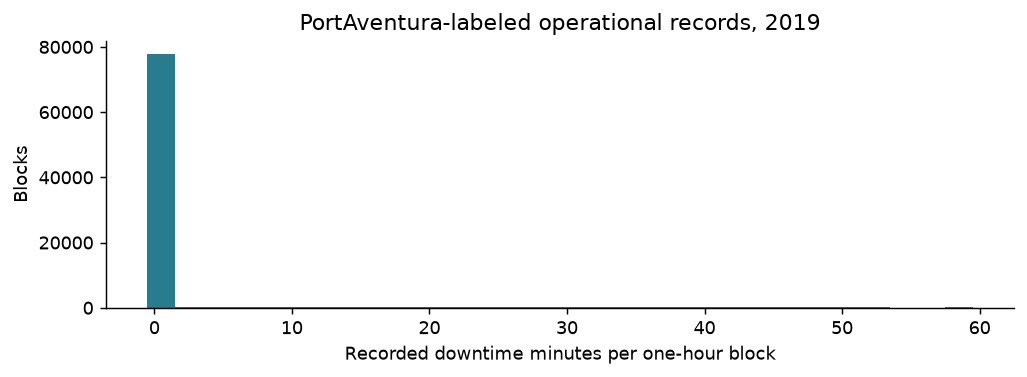

In [3]:
base=pa.loc[reliability_ok & pa.OPEN_TIME.eq(15) & pa.date.dt.year.eq(SOURCE_YEAR)].sort_values(['ATTRACTION','start'])
blocks=[]
for (ride,date),g in base.groupby(['ATTRACTION','date'],sort=False):
    # Non-overlapping complete clock-hour blocks.
    for hour,h in g.groupby(g.start.dt.hour):
        if len(h)==4 and h.start.dt.minute.tolist()==[0,15,30,45]:
            blocks.append(h.DOWNTIME.to_numpy(dtype=float))
blocks=np.asarray(blocks)
assert blocks.shape[1]==4 and len(blocks)>100
np.save(OUT/'portaventura_2019_downtime_blocks.npy',blocks)
source_down=float(blocks.mean()/15)
print(f'{len(blocks):,} contiguous one-hour blocks; reference downtime: {source_down:.3%}')
print('This is external downtime, NOT HKDL downtime.')
fig,ax=plt.subplots(figsize=(8,3))
ax.hist(blocks.sum(axis=1),bins=np.arange(-.5,61.5,2),color='#287c8e')
ax.set(xlabel='Recorded downtime minutes per one-hour block',ylabel='Blocks',title='PortAventura-labeled operational records, 2019')
fig.tight_layout();fig.savefig(OUT/'external_downtime.png');plt.show()


## 3. Published specifications and model inputs

The 2025 HKDL Queue-Times annual and hourly posted-wait summaries provide calibration targets. Posted waits are displayed estimates rather than individual guests' measured waits. Annual and hourly summaries are fitted separately.

**Trip times:** the official HKDL accessibility guide lists 7, 1, 6, 4, 5 and 4 minutes, respectively, for the six rides. These visitor-facing durations are not departure intervals or complete vehicle cycles. Timing boundaries may differ from other published sources.

**Seats per departure:** Hyperspace uses RCDB's 12 riders per train. RC Racer (20) and Iron Man (45) use official sources. Frozen (16) and Mystic Manor (up to 6) use first-hand published reports. Ant-Man's two seats are assumed. Mystic's reported four-carriage dispatch groups are approximated as individual-carriage departures.

**Capacity and departure intervals:** C₀ = 60B/h, where B is seats per departure and h is the interval in minutes. Frozen uses an approximate published capacity of 2,000 guests/hour, giving h = 60 × 16 / 2,000 = 0.48 minutes. This interval is derived, not measured. All other intervals are assumptions; Hyperspace's one-minute interval gives 720 guests/hour.

**Guest flow time:** estimated queue wait plus official trip time. Preshow, loading and transfers are not modeled separately, so this is not a complete measurement of the guest journey.

Sources:
- [Official HKDL accessibility guide](https://secure.cdn1.wdpromedia.com/media/hkdl/guest-services/Guide-Book-Disabilities-2023-ENG.pdf)
- [RCDB: HKDL Hyperspace Mountain](https://rcdb.com/1975.htm)
- [Attractions Magazine: World of Frozen preview](https://attractionsmagazine.com/guide-world-of-frozen-hong-kong-disneyland/)
- [Dejiki: Mystic Manor boarding-area report](https://dejiki.com/2013/12/hkdl-mystic-manor-queue-preshow/)
- [HKDL: RC Racer](https://www.hongkongdisneyland.com/en-hk/attractions/rc-racer/)
- [HKDL/AIA: Iron Man Experience](https://www.aia.com.hk/content/dam/hk/en/pdf/press-release/2016/161107-hkdl-imx-reveal-press-release-e.pdf.coredownload.pdf)


In [4]:
public=json.loads((ROOT/'output/performance_assessment/public_data_2025.json').read_text())
params=pd.DataFrame({
 'ride':public['names'], 'batch_size':[16,20,6,12,45,2],
 'headway_min':[0.48,4.0,0.4,1.0,2.5,0.1],
 'ride_duration_min':[7.0,1.0,6.0,4.0,5.0,4.0],
 'batch_evidence':['first-hand preview report','official seat count','first-hand boarding report','RCDB published train capacity','official seat count','scenario assumption'],
 'headway_evidence':['derived from approximate published capacity']+['scenario assumption']*5,
 'duration_evidence':['official HKDL guide trip time']*6,
 'posted_wait_target_min':public['annual'],
 'wait_source':[f'https://queue-times.com/parks/31/rides/{rid}/2025' for rid in public['ids']]
})
params['duration_source']='https://secure.cdn1.wdpromedia.com/media/hkdl/guest-services/Guide-Book-Disabilities-2023-ENG.pdf'
params['capacity_evidence']=['approximate media-preview estimate']+['calculated from assumed headway']*5
params['nominal_capacity_ph']=params.batch_size*60/params.headway_min
params.to_csv(OUT/'model_inputs.csv',index=False)
display(params.drop(columns='wait_source'))


,ride,batch_size,headway_min,ride_duration_min,batch_evidence,headway_evidence,duration_evidence,posted_wait_target_min,duration_source,capacity_evidence,nominal_capacity_ph
0,Frozen Ever After,16,0.48,7.0,first-hand preview report,derived from approximate published capacity,official HKDL guide trip time,31,https://secure.cdn1.wdpromedia.com/media/hkdl/...,approximate media-preview estimate,2000.0
1,RC Racer,20,4.00,1.0,official seat count,scenario assumption,official HKDL guide trip time,31,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,300.0
2,Mystic Manor,6,0.40,6.0,first-hand boarding report,scenario assumption,official HKDL guide trip time,22,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,900.0
3,Hyperspace Mountain,12,1.00,4.0,RCDB published train capacity,scenario assumption,official HKDL guide trip time,16,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,720.0
4,Iron Man Experience,45,2.50,5.0,official seat count,scenario assumption,official HKDL guide trip time,12,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,1080.0
5,Ant-Man and The Wasp,2,0.10,4.0,scenario assumption,scenario assumption,official HKDL guide trip time,9,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,1200.0


## 4. Batch-service FIFO simulator

Poisson guest arrivals; fixed dispatch headway; a dispatch is cancelled if its scheduled instant falls inside a sampled downtime interval. Each available dispatch boards up to the assumed batch capacity. Unfilled seats are lost, not carried forward. No guests are removed for long waits. After the observation period, arrivals stop and the queue drains; incomplete drainage raises an error rather than dropping long waits.

Queue recursion at departure j: `Q_j=max(0,Q_(j-1)+A_j-B)`. A reflected cumulative-sum implementation is equivalent to this recursion. Each guest's boarding time is recovered from cumulative boardings. Warmup guests create backlog but are excluded from wait statistics. Flow rate uses boardings during the observation window, whereas waits use guests arriving in that window. Both utilization denominators are reported.

Calibration and evaluation use different random seeds. Confidence intervals describe **Monte Carlo uncertainty conditional on assumptions**, not confidence in the true HKDL parameters. The simulation runs continuously for a long representative operating regime; it is not a literal multi-day park schedule.

In [5]:
def boarding_times(arrivals, departures, batch):
    arrived=np.searchsorted(arrivals,departures,side='right')
    net=arrived-batch*np.arange(1,len(departures)+1)
    queue=net-np.minimum.accumulate(np.r_[0,net])[1:]
    served=arrived-queue
    ix=np.searchsorted(served,np.arange(1,len(arrivals)+1),side='left')
    if len(ix) and ix.max()>=len(departures):
        raise RuntimeError('Queue did not drain; extend drain time.')
    return departures[ix],served

def simulate(row,arrival_ph,seed,warm_min=2880,observe_min=10080,down_scale=1.0,capacity_scale=1.0):
    rng=np.random.default_rng(seed)
    stop=warm_min+observe_min
    end=stop+2880  # no arrivals in this drain interval
    n_blocks=int(np.ceil(end/60))
    down=blocks[rng.integers(len(blocks),size=n_blocks)].ravel()
    down=np.minimum(15,down*down_scale)
    starts=np.arange(len(down))*15+rng.random(len(down))*(15-down)
    headway=float(row.headway_min)/capacity_scale
    dep=np.arange(headway,end,headway)
    dep=dep[dep < end-1e-9]  # guard floating-point endpoint inclusion
    slot=np.floor(dep/15).astype(int)
    active=~((dep>=starts[slot])&(dep<starts[slot]+down[slot]))
    dep=dep[active]
    # Exponential interarrivals give a Poisson process. A separate seeded stream
    # preserves common random numbers and monotonic arrivals during rate calibration.
    arng=np.random.default_rng(seed+1000000)
    expected=arrival_ph*stop/60
    count_bound=int(expected+15*np.sqrt(expected)+1000)
    candidates=np.cumsum(arng.exponential(size=count_bound))*60/arrival_ph
    assert candidates[-1]>stop
    arrivals=candidates[candidates<stop]
    count=len(arrivals)
    boarded,served=boarding_times(arrivals,dep,int(row.batch_size))
    cohort=arrivals>=warm_min
    waits=boarded[cohort]-arrivals[cohort]
    board_count=int(((boarded>=warm_min)&(boarded<stop)).sum())
    seats=int(((dep>=warm_min)&(dep<stop)).sum())*int(row.batch_size)
    down_minutes=np.maximum(0,np.minimum(starts+down,stop)-np.maximum(starts,warm_min)).sum()
    q_end=count-int(np.searchsorted(boarded,stop,side='left'))
    assert waits.min()>=-1e-8 and np.all(np.diff(boarded)>=0)
    nominal=float(row.nominal_capacity_ph)*capacity_scale
    return {'wait_min':waits.mean(),'p95_wait_min':np.quantile(waits,.95),
       'flow_ph':board_count/(observe_min/60),'available_capacity_ph':seats/(observe_min/60),
       'util_nominal_pct':100*board_count/(nominal*observe_min/60),
       'util_available_pct':100*board_count/seats,
       'downtime_pct':100*down_minutes/observe_min,
       'queue_at_end':q_end,'arrivals_observation':int(cohort.sum())}

# Independent check of the vectorized FIFO algorithm against a small explicit case.
a=np.array([.1,.2,.3,1.1,3.1]);d=np.arange(1.,7.)
b,s=boarding_times(a,d,2)
assert np.array_equal(b,np.array([1.,1.,2.,2.,4.]))
assert s[-1]==len(a)
print('FIFO, conservation, and drain check passed.')


FIFO, conservation, and drain check passed.


## 5. Annual waiting-time calibration

Only arrival rate is adjusted while capacity and downtime assumptions remain fixed. A bisection fit matches the mean over calibration replications. Upper bound = 99.95% of nominal capacity × mean external availability; this keeps the intended long-run load below available capacity. If a target cannot be bracketed, it is flagged as unmatched, not silently claimed as fitted.

Because the target is posted wait, the baseline assumes posted and experienced means coincide. This assumption is tested later. These estimates are one feasible parameterization, not uniquely recovered demand.

In [6]:
CAL_SEEDS=list(range(27030,27094))
EVAL_SEEDS=list(range(80000,80128))
wait_cache={}
def mean_wait(row,rate,seeds=CAL_SEEDS):
    key=(row.ride,float(rate),tuple(seeds))
    if key not in wait_cache:
        wait_cache[key]=float(np.mean([simulate(row,rate,s)['wait_min'] for s in seeds]))
    return wait_cache[key]

def calibrate(row,target,seeds=CAL_SEEDS,steps=13):
    lo=float(row.nominal_capacity_ph)*.05
    hi=float(row.nominal_capacity_ph)*(1-source_down)*.9995
    wl=mean_wait(row,lo,seeds);wh=mean_wait(row,hi,seeds)
    if not wl<=target<=wh:
        rate=lo if target<wl else hi
        return rate,mean_wait(row,rate,seeds),False
    for _ in range(steps):
        mid=(lo+hi)/2
        if mean_wait(row,mid,seeds)<target:lo=mid
        else:hi=mid
    rate=(lo+hi)/2
    fit=mean_wait(row,rate,seeds)
    return rate,fit,abs(fit-target)<=1.0

fit_rows=[]
for row in params.itertuples(index=False):
    rate,fit,ok=calibrate(row,row.posted_wait_target_min)
    fit_rows.append({'ride':row.ride,'arrival_ph':rate,'fit_wait_min':fit,'fit_ok':ok,
                     'target_min':row.posted_wait_target_min})
    print(row.ride,round(rate,1),'guests/h; target',row.posted_wait_target_min,'fit',round(fit,2),'matched',ok,flush=True)
fits=pd.DataFrame(fit_rows)
fits.to_csv(OUT/'annual_calibration.csv',index=False)


Frozen Ever After 1878.4 guests/h; target 31 fit 30.97 matched True


RC Racer 280.1 guests/h; target 31 fit 30.97 matched True


Mystic Manor 832.7 guests/h; target 22 fit 21.98 matched True


Hyperspace Mountain 654.9 guests/h; target 16 fit 15.98 matched True


Iron Man Experience 959.6 guests/h; target 12 fit 11.99 matched True


Ant-Man and The Wasp 1048.3 guests/h; target 9 fit 9.0 matched True


## 6. Independent evaluation and scenario comparisons

Evaluation uses 128 replications with seeds disjoint from calibration. Capacity +10% and outage duration -50% hold calibrated arrivals fixed. Demand +10% is a stress test; doubled warmup assesses transient effects. Paired differences compare each scenario with the baseline under common random seeds. Monte Carlo confidence intervals describe numerical uncertainty conditional on the inputs, not uncertainty in the actual HKDL parameters.

In [7]:
records=[]
scenarios={'Baseline':{},'Capacity +10%':{'capacity_scale':1.1},'Downtime duration -50%':{'down_scale':.5},'Demand +10%':{'arrival_multiplier':1.1},'Double warmup':{'warm_min':5760}}
for row in params.itertuples(index=False):
    rate=float(fits.loc[fits.ride.eq(row.ride),'arrival_ph'].iloc[0])
    for scenario,kwargs in scenarios.items():
        opts=kwargs.copy();r=rate*opts.pop('arrival_multiplier',1)
        for seed in EVAL_SEEDS:
            value=simulate(row,r,seed,**opts)
            records.append({'ride':row.ride,'scenario':scenario,'seed':seed,'arrival_ph':r,**value})
runs=pd.DataFrame(records)
runs.to_csv(OUT/'simulation_replications.csv',index=False)
metrics=['wait_min','p95_wait_min','flow_ph','available_capacity_ph','util_nominal_pct','util_available_pct','downtime_pct','queue_at_end']
summary=runs.groupby(['ride','scenario'])[metrics].mean().reset_index()
errors=runs.groupby(['ride','scenario']).wait_min.agg(['std','count']).reset_index()
summary=summary.merge(errors,on=['ride','scenario'])
summary['wait_mc95_halfwidth']=t.ppf(.975,summary['count']-1)*summary['std']/np.sqrt(summary['count'])
summary.to_csv(OUT/'scenario_summary.csv',index=False)
result=summary[summary.scenario.eq('Baseline')].merge(params[['ride','ride_duration_min','nominal_capacity_ph','posted_wait_target_min']],on='ride').merge(fits[['ride','arrival_ph','fit_wait_min','fit_ok']],on='ride')
result['time_in_system_min']=result.wait_min+result.ride_duration_min
result['evaluation_error_min']=result.wait_min-result.posted_wait_target_min
result=result.set_index('ride').reindex(public['names']).reset_index()
result.to_csv(OUT/'six_ride_results.csv',index=False)
display(result[['ride','posted_wait_target_min','fit_wait_min','wait_min','wait_mc95_halfwidth','flow_ph','util_nominal_pct','util_available_pct','downtime_pct','time_in_system_min']].round(2))
assert result.ride.nunique()==6
assert runs.util_available_pct.between(0,100+1e-8).all()

paired=[]
for (ride,scenario),g in runs.groupby(['ride','scenario']):
    if scenario=='Baseline': continue
    b=runs.loc[runs.ride.eq(ride)&runs.scenario.eq('Baseline'),['seed','wait_min']]
    z=g[['seed','wait_min']].merge(b,on='seed',suffixes=('_scenario','_base'))
    delta=z.wait_min_scenario-z.wait_min_base
    paired.append({'ride':ride,'scenario':scenario,'wait_difference_min':delta.mean(),
       'mc95_halfwidth':t.ppf(.975,len(delta)-1)*delta.std(ddof=1)/np.sqrt(len(delta))})
pd.DataFrame(paired).to_csv(OUT/'paired_scenario_effects.csv',index=False)
print('Evaluation and paired comparisons complete.',flush=True)


,ride,posted_wait_target_min,fit_wait_min,wait_min,wait_mc95_halfwidth,flow_ph,util_nominal_pct,util_available_pct,downtime_pct,time_in_system_min
0,Frozen Ever After,31,30.97,23.66,3.82,1876.07,93.80,97.07,3.35,30.66
1,RC Racer,31,30.97,23.76,3.38,279.63,93.21,96.46,3.35,24.76
2,Mystic Manor,22,21.98,16.26,2.29,831.86,92.43,95.64,3.35,22.26
3,Hyperspace Mountain,16,15.98,12.12,1.23,654.39,90.89,94.05,3.35,16.12
4,Iron Man Experience,12,11.99,9.57,0.86,959.08,88.80,91.87,3.35,14.57
5,Ant-Man and The Wasp,9,9.00,7.29,0.71,1047.84,87.32,90.36,3.35,11.29


Evaluation and paired comparisons complete.


## 7. Descriptive monthly and hourly performance

Monthly and hourly inputs were checked against the six Queue-Times 2025 attraction pages on 23 October 2026. The source-published annual mean is retained separately. Monthly SD uses the sample convention (ddof=1); CV divides this SD by the unweighted mean of the twelve monthly values, not the source annual mean. These statistics describe variation between monthly averages, not individual guest waits. Hourly peaks are restricted to the common 11:00-20:00 window to improve comparability. All inputs are rounded published summaries; underlying sample sizes and weights are unavailable.

In [8]:
months=np.asarray(public['monthly'],dtype=float)
hours=np.asarray(public['hourly'],dtype=float)
assert months.shape==(6,12) and hours.shape==(6,10)
descriptive=pd.DataFrame({'ride':public['names'],'source_annual_mean':public['annual'],
    'monthly_mean':months.mean(axis=1),'monthly_sd':months.std(axis=1,ddof=1),
    'monthly_cv':months.std(axis=1,ddof=1)/months.mean(axis=1),
    'monthly_min':months.min(axis=1),'monthly_max':months.max(axis=1),
    'peak_hour':[public['hours'][i] for i in hours.argmax(axis=1)],
    'peak_hour_wait':hours.max(axis=1),'wait_at_20':hours[:,-1]})
descriptive.to_csv(OUT/'observed_wait_summary.csv',index=False)
monthly_long=pd.DataFrame(months.T,index=range(1,13),columns=public['names'])
monthly_long.index.name='month'
monthly_long.to_csv(OUT/'verified_monthly_waits_2025.csv')
display(descriptive.round(3))


,ride,source_annual_mean,monthly_mean,monthly_sd,monthly_cv,monthly_min,monthly_max,peak_hour,peak_hour_wait,wait_at_20
0,Frozen Ever After,31,30.750,10.001,0.325,18.0,47.0,15,47.0,15.0
1,RC Racer,31,30.667,6.760,0.220,21.0,40.0,16,43.0,21.0
2,Mystic Manor,22,21.583,5.946,0.275,14.0,32.0,15,39.0,9.0
3,Hyperspace Mountain,16,16.250,5.101,0.314,10.0,25.0,15,23.0,11.0
4,Iron Man Experience,12,12.000,2.412,0.201,9.0,17.0,15,18.0,8.0
5,Ant-Man and The Wasp,9,9.250,2.050,0.222,7.0,13.0,15,15.0,6.0


## 8. Performance comparisons

The figures distinguish published waiting-time targets from simulated results. Throughput and utilization comparisons depend on the capacity assumptions; they do not establish measured rankings across HKDL rides. A close calibration fit alone does not validate the estimated throughput.

The sensitivity comparisons show how waiting changes under alternative operating conditions. Growing queues in the demand stress test indicate overload within the model rather than a forecast for a specific operating day.


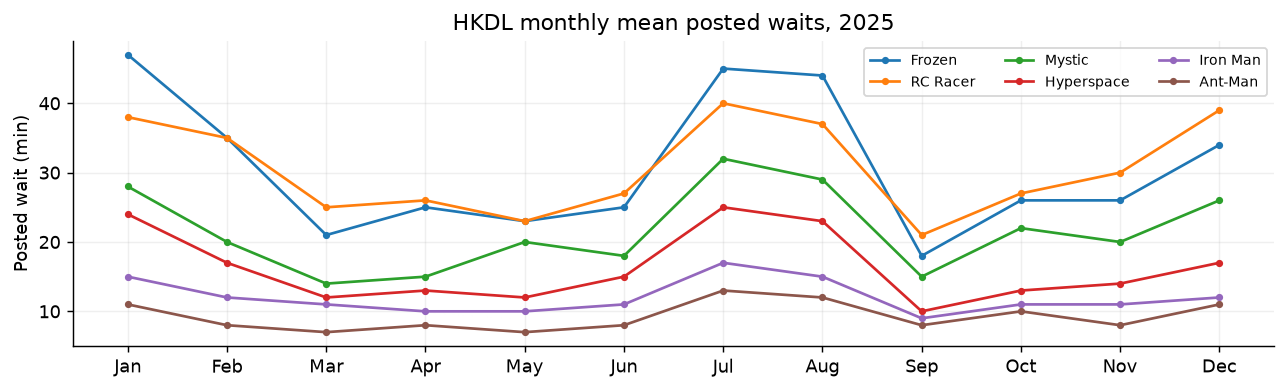

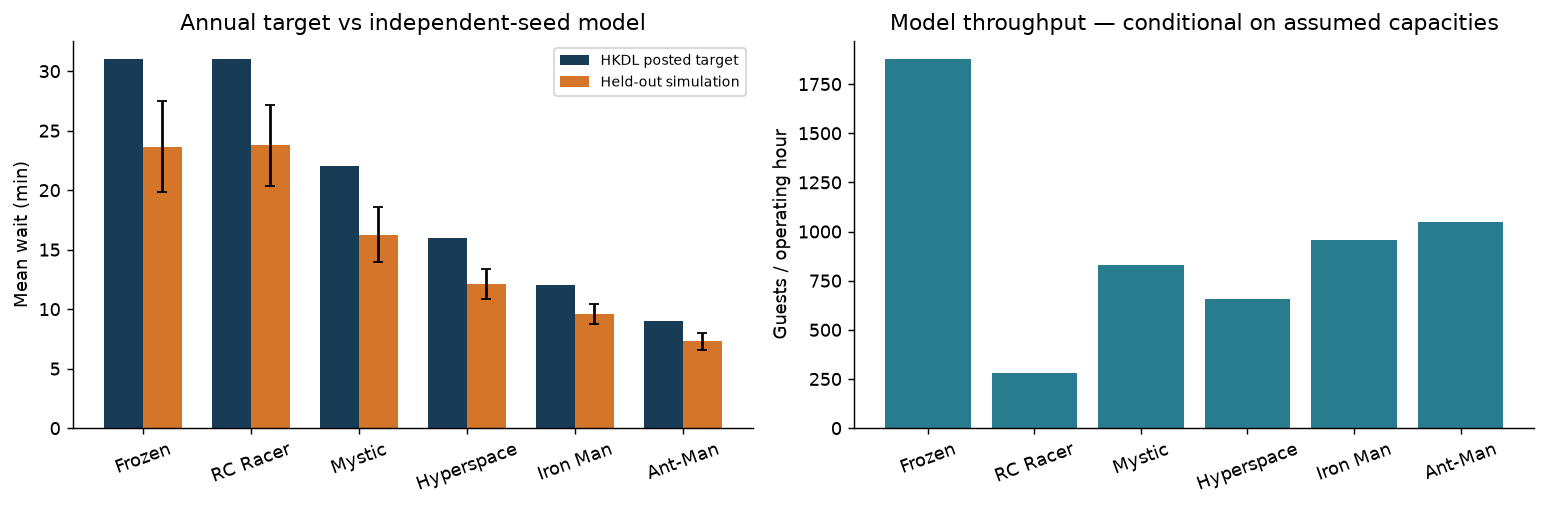

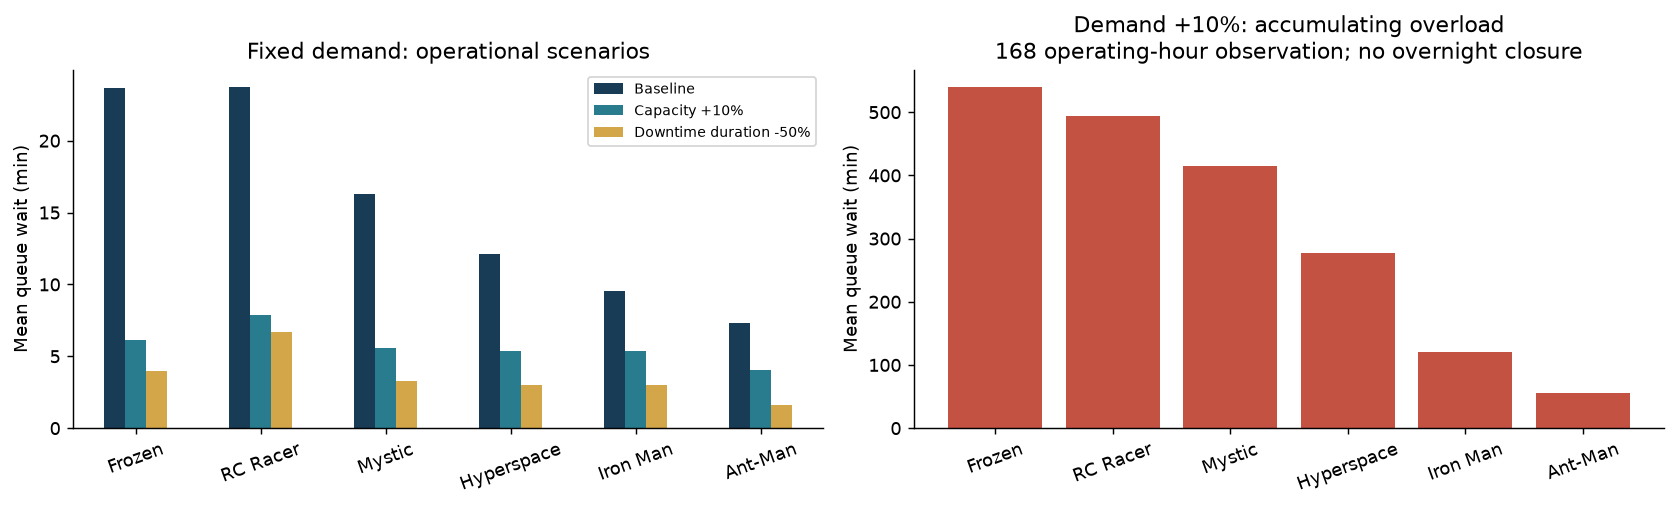

,warmup_change_min,review_transient_sensitivity
ride,,
Ant-Man and The Wasp,0.58,False
Frozen Ever After,3.47,True
Hyperspace Mountain,1.09,False
Iron Man Experience,0.64,False
Mystic Manor,1.96,False
RC Racer,2.54,True


Annual fits within 1 min: 6 / 6
Unmatched targets and material warmup differences must be disclosed; do not report them as validated results.


,ride,posted_wait_target_min,wait_min,evaluation_error_min,wait_mc95_halfwidth,within_2min_of_target
0,Frozen Ever After,31,23.66,-7.34,3.82,False
1,RC Racer,31,23.76,-7.24,3.38,False
2,Mystic Manor,22,16.26,-5.74,2.29,False
3,Hyperspace Mountain,16,12.12,-3.88,1.23,False
4,Iron Man Experience,12,9.57,-2.43,0.86,False
5,Ant-Man and The Wasp,9,7.29,-1.71,0.71,True


Calibration is not independent validation. Review seed uncertainty before using point estimates in the report.


In [9]:
labels=['Frozen','RC Racer','Mystic','Hyperspace','Iron Man','Ant-Man']
fig,ax=plt.subplots(figsize=(10,3.1))
for i,label in enumerate(labels):
    ax.plot(range(1,13),months[i],marker='o',markersize=3,label=label)
ax.set(xticks=range(1,13),xticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],ylabel='Posted wait (min)',title='HKDL monthly mean posted waits, 2025')
ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'monthly_waits.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
x=np.arange(6);labels=['Frozen','RC Racer','Mystic','Hyperspace','Iron Man','Ant-Man']
axes[0].bar(x-.18,result.posted_wait_target_min,.36,label='HKDL posted target',color='#183b56')
axes[0].bar(x+.18,result.wait_min,.36,yerr=result.wait_mc95_halfwidth,label='Held-out simulation',color='#d47529',capsize=3)
axes[0].set(ylabel='Mean wait (min)',title='Annual target vs independent-seed model')
axes[0].legend(fontsize=8)
axes[1].bar(x,result.flow_ph,color='#287c8e')
axes[1].set(ylabel='Guests / operating hour',title='Model throughput — conditional on assumed capacities')
for ax in axes:ax.set_xticks(x,labels,rotation=20)
fig.tight_layout();fig.savefig(OUT/'baseline_results.png');plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4))
pivot=summary[summary.scenario.isin(['Baseline','Capacity +10%','Downtime duration -50%'])].pivot(index='ride',columns='scenario',values='wait_min').reindex(public['names'])
pivot.index=labels
pivot.plot.bar(ax=axes[0],color=['#183b56','#287c8e','#d4a64a'])
axes[0].set(ylabel='Mean queue wait (min)',xlabel='',title='Fixed demand: operational scenarios')
stress=summary[summary.scenario.eq('Demand +10%')].set_index('ride').reindex(public['names'])
axes[1].bar(labels,stress.wait_min,color='#c35243')
axes[1].set(ylabel='Mean queue wait (min)',title='Demand +10%: accumulating overload\n168 operating-hour observation; no overnight closure')
for ax in axes: ax.tick_params(axis='x',rotation=20)
axes[0].legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'sensitivity.png');plt.show()

warm=summary.pivot(index='ride',columns='scenario',values='wait_min')
checks=pd.DataFrame({'warmup_change_min':warm['Double warmup']-warm.Baseline})
checks['review_transient_sensitivity']=checks.warmup_change_min.abs()>2
checks.to_csv(OUT/'warmup_check.csv')
display(checks.round(2))
print('Annual fits within 1 min:', int(fits.fit_ok.sum()),'/ 6')

print('Unmatched targets and material warmup differences must be disclosed; do not report them as validated results.')

validation=result[['ride','posted_wait_target_min','wait_min','evaluation_error_min','wait_mc95_halfwidth']].copy()
validation['within_2min_of_target']=validation.evaluation_error_min.abs()<=2
validation.to_csv(OUT/'independent_seed_check.csv',index=False)
display(validation.round(2))
print('Calibration is not independent validation. Review seed uncertainty before using point estimates in the report.')


## 9. Interpretation and limitations

Published annual means summarize the waiting-time level; monthly CV summarizes seasonal variation. Neither establishes the cause of congestion. The queueing model uses published or assumed service parameters and an external downtime distribution. Matching posted means by adjusting arrivals does not independently validate throughput or utilization.

Scenario differences are conditional comparisons, not measured benefits of staffing or maintenance changes. The capacity and downtime interventions differ in magnitude and cost, so they cannot establish cost-effectiveness. Actual dispatch intervals, guest counts, outage logs and opening schedules are required for operational validation. The six rides are modeled separately although demand can shift between them in practice.